<a href="https://colab.research.google.com/github/almutairij795-byte/00-Setup-Git/blob/master/lap4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, exposure, img_as_float
from google.colab.patches import cv2_imshow

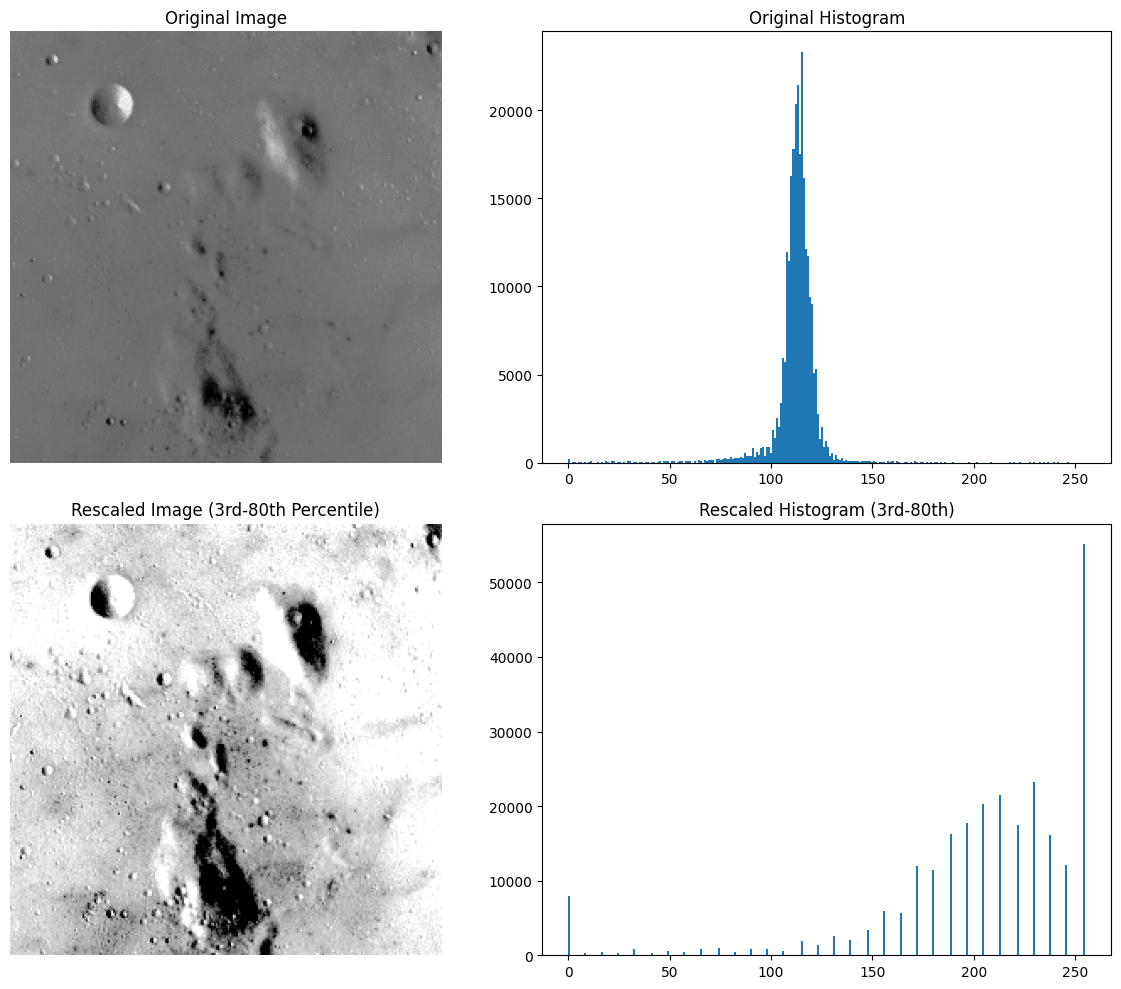

In [3]:

# Load the moon image [cite: 43, 44]
img = data.moon()

# Task 1: Rescale intensity values to include all intensities
# between the 3rd and 80th percentiles
p3, p80 = np.percentile(img, (3, 80))
img_rescale = exposure.rescale_intensity(img, in_range=(p3, p80))

# Plotting the results
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Original Image
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

# Original Histogram [cite: 59]
axes[0, 1].hist(img.flat, bins=256, range=(0, 255))
axes[0, 1].set_title('Original Histogram')

# Rescaled Image (3rd-80th percentile)
axes[1, 0].imshow(img_rescale, cmap='gray')
axes[1, 0].set_title('Rescaled Image (3rd-80th Percentile)')
axes[1, 0].axis('off')

# Rescaled Histogram
axes[1, 1].hist(img_rescale.flat, bins=256, range=(0, 255))
axes[1, 1].set_title('Rescaled Histogram (3rd-80th)')

plt.tight_layout()
plt.show()

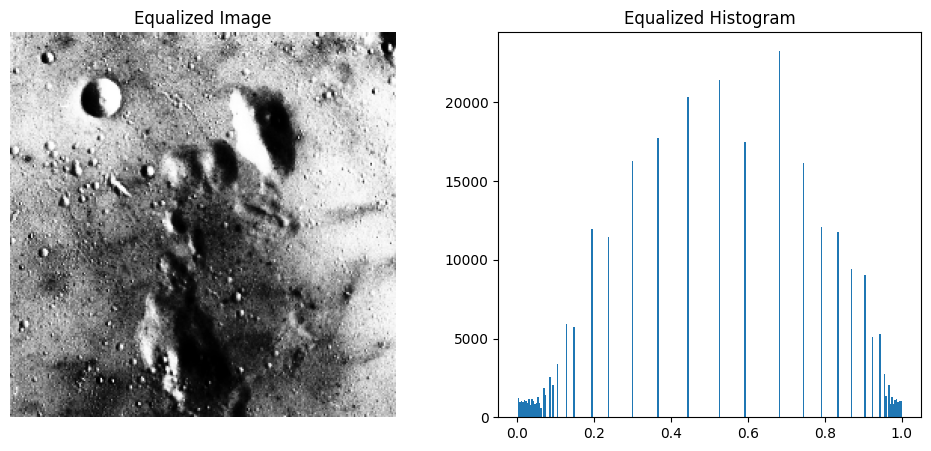

In [4]:
# Task 2: Histogram Equalization
img_eq = exposure.equalize_hist(img)

# Plotting the results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Equalized Image
axes[0].imshow(img_eq, cmap='gray')
axes[0].set_title('Equalized Image')
axes[0].axis('off')

# Equalized Histogram
axes[1].hist(img_eq.flat, bins=256)
axes[1].set_title('Equalized Histogram')

plt.show()

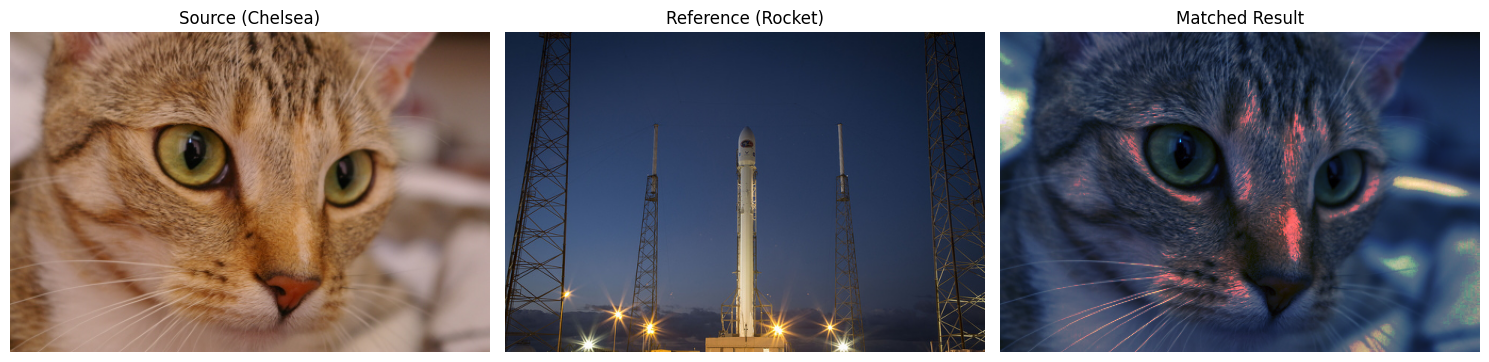

In [5]:
from skimage.exposure import match_histograms

# Task 3: Histogram Matching
# Load images from skimage.data
image = data.chelsea()  # The image to be matched
reference = data.rocket() # The reference image

# Perform histogram matching
# multichannel=True is used for color images
matched = match_histograms(image, reference, channel_axis=-1)

# Plotting the comparison
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

for ax in (ax1, ax2, ax3):
    ax.axis('off')

ax1.imshow(image)
ax1.set_title('Source (Chelsea)')

ax2.imshow(reference)
ax2.set_title('Reference (Rocket)')

ax3.imshow(matched)
ax3.set_title('Matched Result')

plt.tight_layout()
plt.show()